## Screen time vs. mental health with real(!) data

Data card: https://www.kaggle.com/datasets/kylefengkfeng209/screen-time-vs-mental-health-ml-ready?select=bdi_and_screen_items.csv

### Setup and data import

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import seaborn as sns
%matplotlib inline
sns.set_theme()
import statsmodels.api as sm
from scipy import stats

In [2]:
screen = pd.read_csv('data/screen_time_mental_health.csv')

### Exploratory analysis

In [3]:
screen.head()

,subject_id,sex,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
0,1,Boy,3.333,4.64,2.25,8.36,4.58,1.92,6,0
1,2,Girl,3.333,4.07,2.50,7.31,5.42,2.25,7,0
2,3,Boy,3.333,4.07,2.00,8.75,5.50,2.62,27,1
3,4,Boy,4.333,6.07,1.50,8.17,6.62,3.96,22,1
4,5,Boy,1.667,0.50,2.50,8.88,4.12,1.79,3,0


In [4]:
screen.describe()

,subject_id,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
count,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000,4810.000000
mean,2405.500000,3.219097,3.958299,1.901611,7.689067,5.570553,2.400200,7.271518,0.163617
std,1388.671727,1.026348,2.387289,0.851176,1.270213,1.415505,1.137931,7.703156,0.369967
min,1.000000,1.000000,0.500000,1.000000,1.360000,1.670000,-3.030000,0.000000,0.000000
25%,1203.250000,2.333000,2.070000,1.250000,7.050000,4.540000,1.580000,2.000000,0.000000
50%,2405.500000,3.000000,3.500000,1.750000,7.870000,5.420000,2.290000,5.000000,0.000000
75%,3607.750000,4.000000,5.500000,2.250000,8.540000,6.500000,3.120000,10.000000,0.000000
max,4810.000000,6.000000,10.000000,6.000000,12.210000,10.500000,6.960000,51.000000,1.000000


array([[<Axes: title={'center': 'subject_id'}>,
        <Axes: title={'center': 'screen_time_index'}>,
        <Axes: title={'center': 'est_leisure_screen_hours'}>],
       [<Axes: title={'center': 'sleep_quality_index'}>,
        <Axes: title={'center': 'avg_sleep_hours'}>,
        <Axes: title={'center': 'midsleep_weekend_hours'}>],
       [<Axes: title={'center': 'social_jetlag_hours'}>,
        <Axes: title={'center': 'bdi_total'}>,
        <Axes: title={'center': 'depressed'}>]], dtype=object)

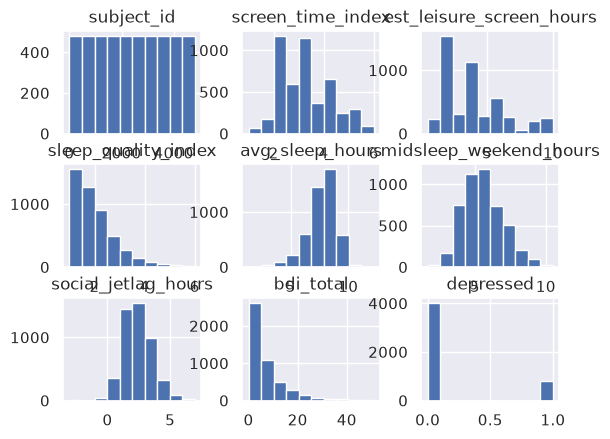

In [5]:
screen.hist()

In [6]:
corr = screen.corr(numeric_only=True)
corr

,subject_id,screen_time_index,est_leisure_screen_hours,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours,bdi_total,depressed
subject_id,1.000000,0.010429,0.000799,-0.017118,-0.007446,-0.017823,-0.012649,-0.000147,0.008411
screen_time_index,0.010429,1.000000,0.935067,0.092327,-0.256280,0.286531,0.182000,0.134377,0.090661
est_leisure_screen_hours,0.000799,0.935067,1.000000,0.071959,-0.227361,0.264168,0.164165,0.107172,0.066186
sleep_quality_index,-0.017118,0.092327,0.071959,1.000000,-0.318088,0.124462,0.022253,0.380581,0.311798
avg_sleep_hours,-0.007446,-0.256280,-0.227361,-0.318088,1.000000,-0.517585,-0.163678,-0.260253,-0.193602
midsleep_weekend_hours,-0.017823,0.286531,0.264168,0.124462,-0.517585,1.000000,0.837755,0.148764,0.119636
social_jetlag_hours,-0.012649,0.182000,0.164165,0.022253,-0.163678,0.837755,1.000000,0.071679,0.060671
bdi_total,-0.000147,0.134377,0.107172,0.380581,-0.260253,0.148764,0.071679,1.000000,0.815114
depressed,0.008411,0.090661,0.066186,0.311798,-0.193602,0.119636,0.060671,0.815114,1.000000


<Axes: >

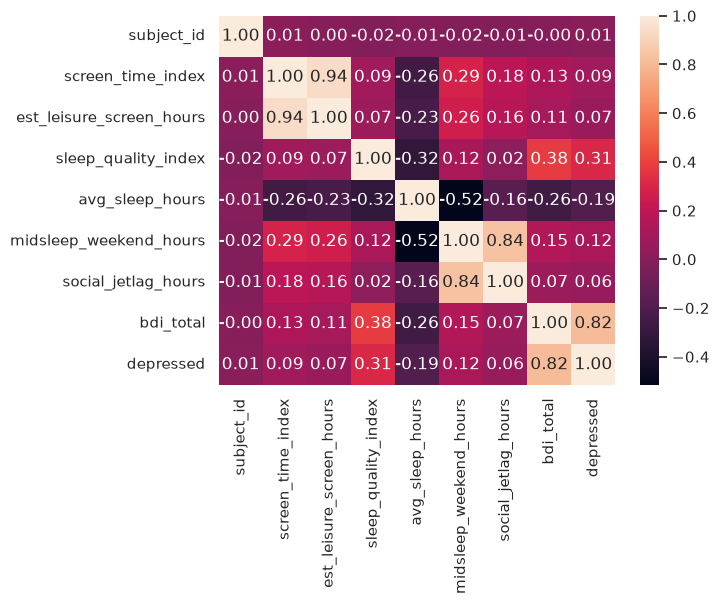

In [7]:
sns.heatmap(corr,annot=True,fmt=".2f")

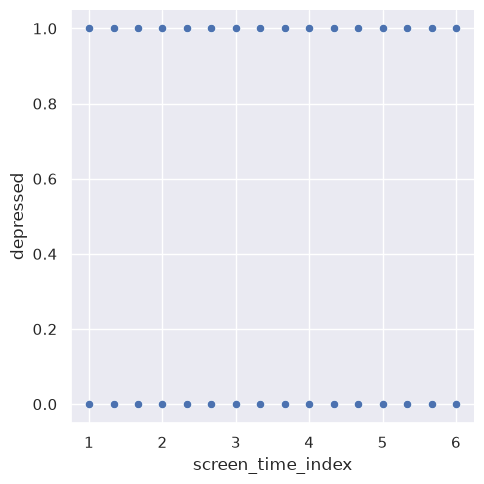

In [8]:
sns.relplot(x='screen_time_index',y='depressed',data=screen)

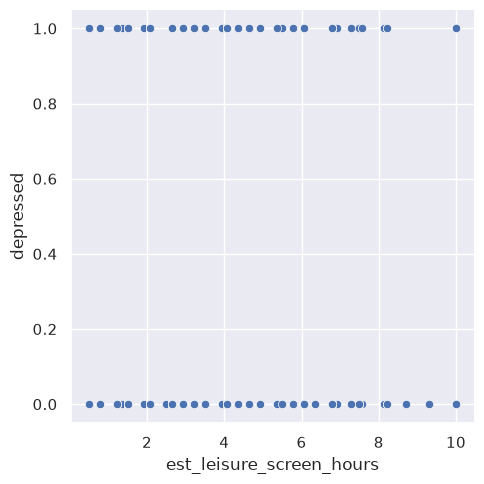

In [9]:
sns.relplot(x='est_leisure_screen_hours',y='depressed',data=screen)

<Axes: xlabel='screen_time_index', ylabel='depressed'>

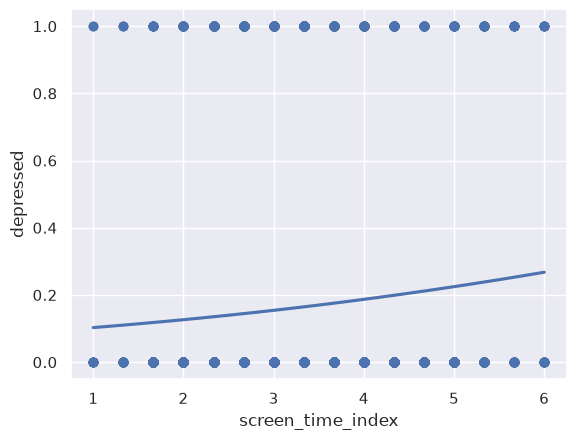

In [34]:
sns.regplot(x='screen_time_index',y='depressed',logistic=True,ci=None,data=screen)

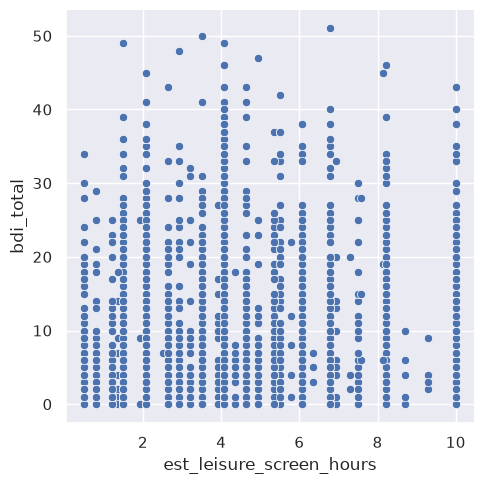

In [11]:
sns.relplot(x='est_leisure_screen_hours',y='bdi_total',data=screen)

<Axes: xlabel='est_leisure_screen_hours', ylabel='bdi_total'>

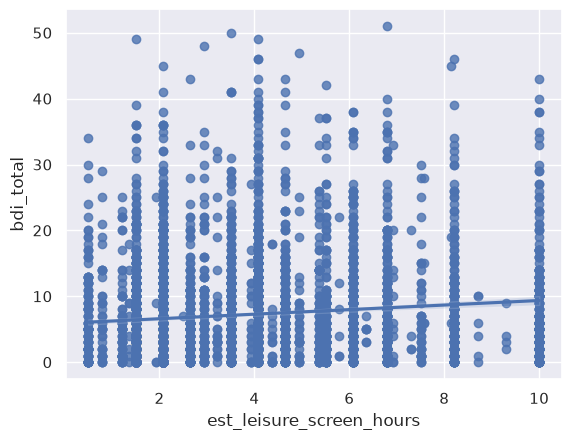

In [12]:
sns.regplot(x='est_leisure_screen_hours',y='bdi_total',data=screen)

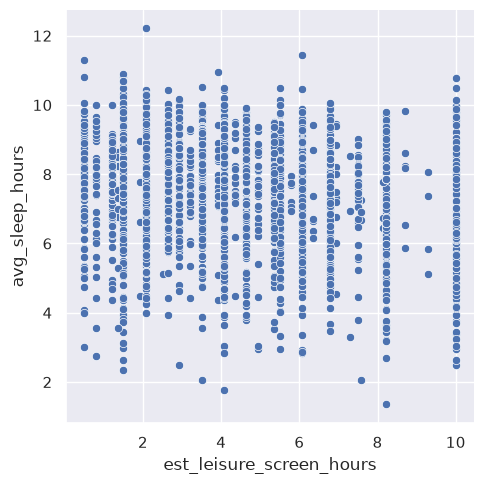

In [13]:
sns.relplot(x='est_leisure_screen_hours',y='avg_sleep_hours',data=screen)

<Axes: xlabel='est_leisure_screen_hours', ylabel='avg_sleep_hours'>

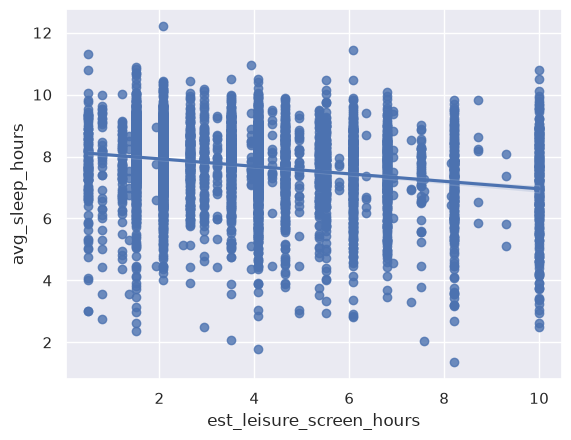

In [14]:
sns.regplot(x='est_leisure_screen_hours',y='avg_sleep_hours',data=screen)

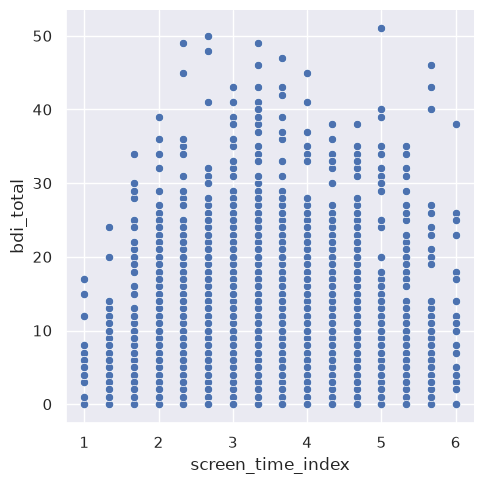

In [15]:
sns.relplot(x='screen_time_index',y='bdi_total',data=screen)

<Axes: xlabel='screen_time_index', ylabel='bdi_total'>

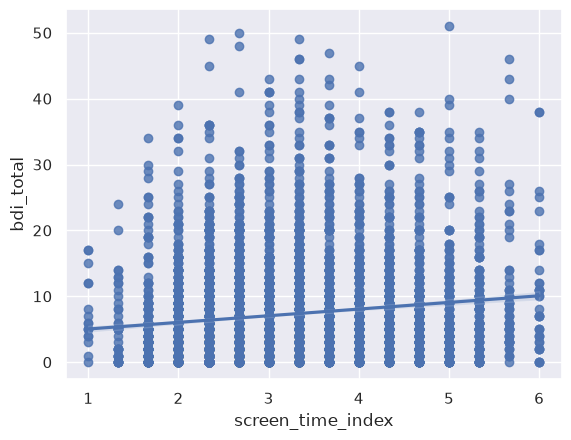

In [16]:
sns.regplot(x='screen_time_index',y='bdi_total',data=screen)

<Axes: xlabel='screen_time_index', ylabel='bdi_total'>

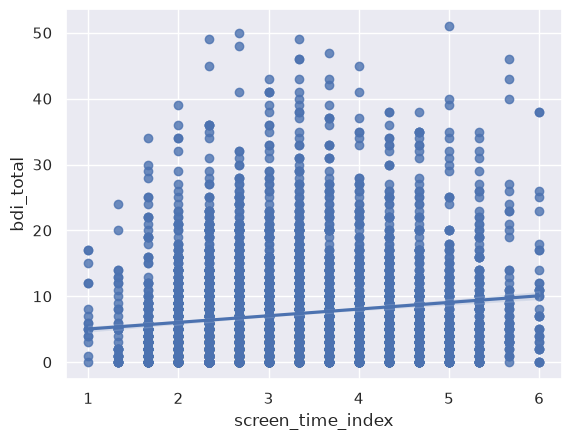

In [17]:
sns.regplot(x='screen_time_index',y='bdi_total',data=screen)

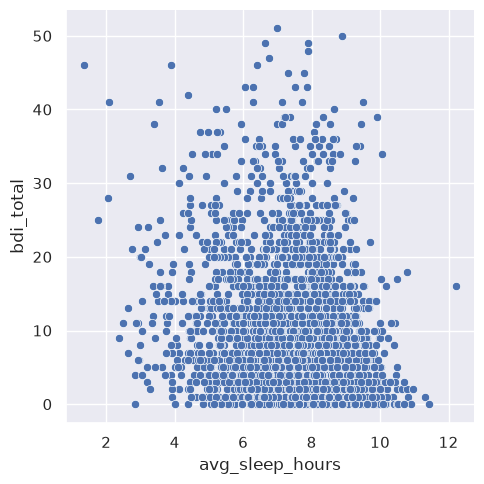

In [18]:
sns.relplot(x='avg_sleep_hours',y='bdi_total',data=screen)

<Axes: xlabel='avg_sleep_hours', ylabel='bdi_total'>

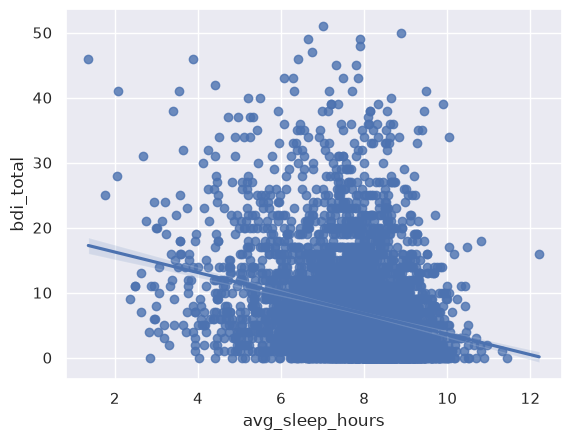

In [19]:
sns.regplot(x='avg_sleep_hours',y='bdi_total',data=screen)

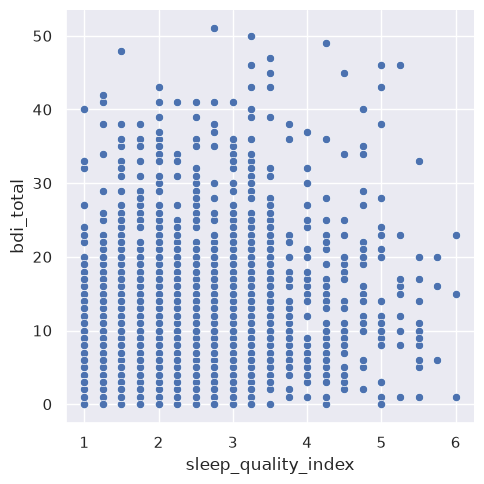

In [20]:
sns.relplot(x='sleep_quality_index',y='bdi_total',data=screen)

<Axes: xlabel='sleep_quality_index', ylabel='bdi_total'>

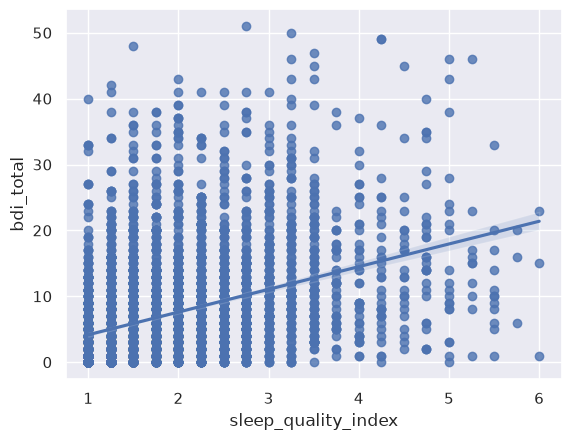

In [21]:
sns.regplot(x='sleep_quality_index',y='bdi_total',data=screen)

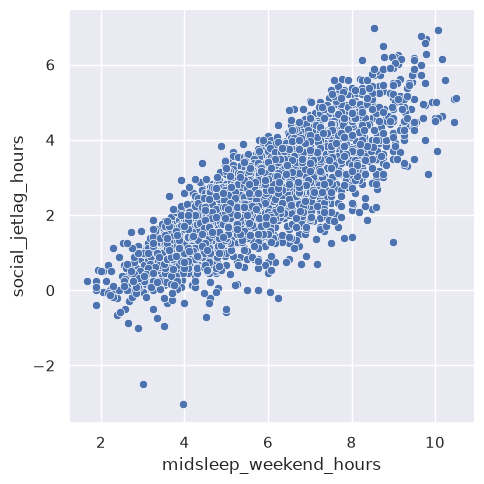

In [22]:
sns.relplot(x='midsleep_weekend_hours',y='social_jetlag_hours',data=screen)

<Axes: xlabel='midsleep_weekend_hours', ylabel='social_jetlag_hours'>

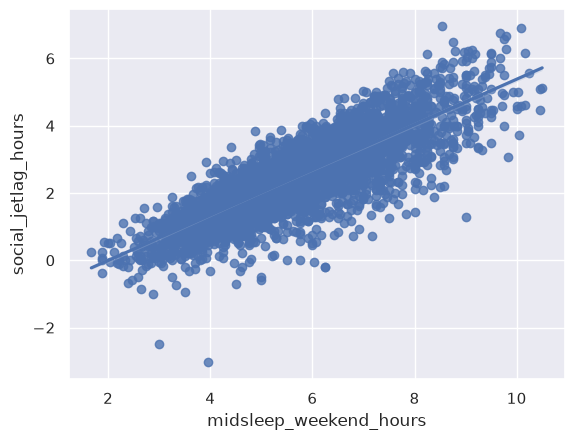

In [23]:
sns.regplot(x='midsleep_weekend_hours',y='social_jetlag_hours',data=screen)

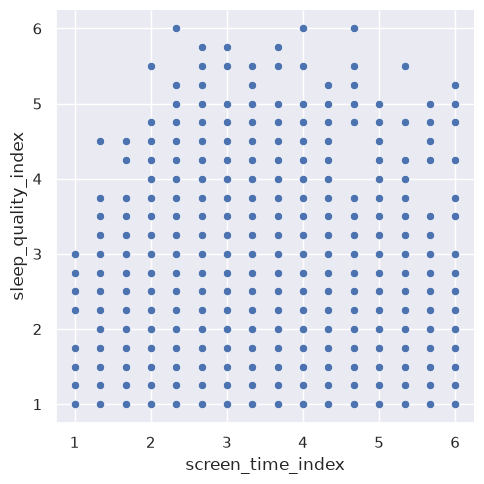

In [24]:
sns.relplot(x='screen_time_index',y='sleep_quality_index',data=screen)

<Axes: xlabel='screen_time_index', ylabel='sleep_quality_index'>

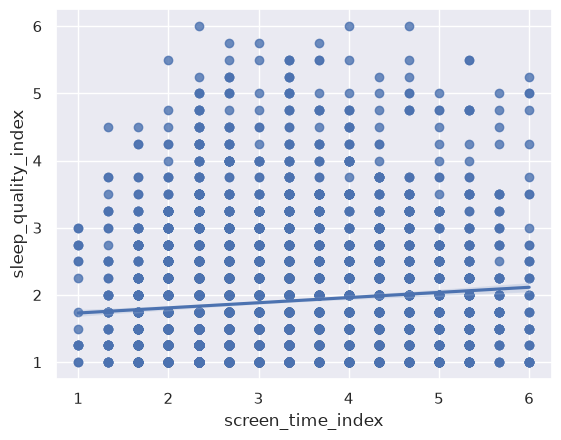

In [25]:
sns.regplot(x='screen_time_index',y='sleep_quality_index',data=screen)

### Modeling

In [26]:
results = smf.ols('bdi_total ~ screen_time_index + est_leisure_screen_hours + sleep_quality_index + avg_sleep_hours + midsleep_weekend_hours + social_jetlag_hours',data=screen).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              bdi_total   R-squared:                       0.173
Model:                            OLS   Adj. R-squared:                  0.172
Method:                 Least Squares   F-statistic:                     167.5
Date:                Tue, 28 Jul 2026   Prob (F-statistic):          6.51e-194
Time:                        19:14:28   Log-Likelihood:                -16188.
No. Observations:                4810   AIC:                         3.239e+04
Df Residuals:                    4803   BIC:                         3.244e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    6.0341      1.580      3.818      0.000       2.936       9.132
screen_time_index            1.1518      0.281      4.101      0.000       0.601       1.702
est_leisure_screen_hours    -0.3013      0.120     -2.517      0.012      -0.536      -0.067
sleep_quality_index          2.9844      0.126     23.771      0.000       2.738       3.230
avg_sleep_hours             -0.8863      0.119     -7.479      0.000      -1.119      -0.654
midsleep_weekend_hours      -0.1922      0.187     -1.031      0.303      -0.558       0.173
social_jetlag_hours          0.3886      0.200      1.946      0.052      -0.003       0.780
==============================================================================
Omnibus:                     1718.540   Durbin-Watson:                   2.010
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             6523.211
Skew:                           1.762   Prob(JB):                         0.00
Kurtosis:                       7.487   Cond. No.                         180.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

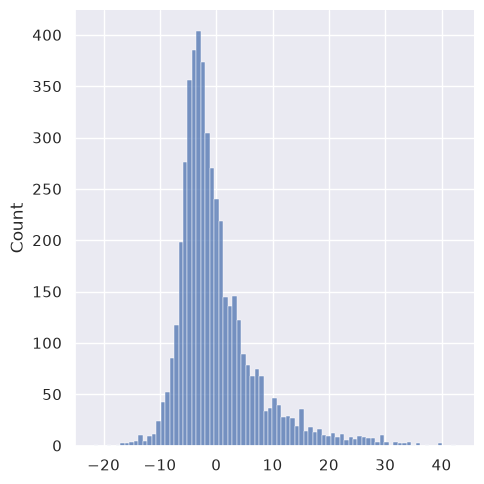

In [27]:
sns.displot(results.resid)

In [28]:
results = smf.logit('depressed ~ screen_time_index + est_leisure_screen_hours + sleep_quality_index + avg_sleep_hours + midsleep_weekend_hours + social_jetlag_hours',data=screen).fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.396482
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              depressed   No. Observations:                 4810
Model:                          Logit   Df Residuals:                     4803
Method:                           MLE   Df Model:                            6
Date:                Tue, 28 Jul 2026   Pseudo R-squ.:                  0.1103
Time:                        19:14:29   Log-Likelihood:                -1907.1
converged:                       True   LL-Null:                       -2143.4
Covariance Type:            nonrobust   LLR p-value:                 6.335e-99
============================================================================================
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -2.8091      0.626     -4.484      0.000      -4.037      -1.581
screen_time_index            0.3987      0.112      3.557      0.000       0.179       0.618
est_leisure_screen_hours    -0.1361      0.048     -2.835      0.005      -0.230      -0.042
sleep_quality_index          0.7457      0.045     16.404      0.000       0.657       0.835
avg_sleep_hours             -0.1828      0.046     -3.937      0.000      -0.274      -0.092
midsleep_weekend_hours       0.0060      0.073      0.082      0.935      -0.137       0.149
social_jetlag_hours          0.0801      0.078      1.032      0.302      -0.072       0.232
============================================================================================
"""

Sleep seems to have a negative correlation with depression, same as with I've seen with the simulated data.

In [29]:
results = smf.ols('bdi_total ~ sleep_quality_index',data=screen).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              bdi_total   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     814.4
Date:                Tue, 28 Jul 2026   Prob (F-statistic):          1.32e-165
Time:                        19:14:29   Log-Likelihood:                -16269.
No. Observations:                4810   AIC:                         3.254e+04
Df Residuals:                    4808   BIC:                         3.255e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.7219      0.251      2.871      0.004       0.229       1.215
sleep_quality_index     3.4443      0.121     28.537      0.000       3.208       3.681
==============================================================================
Omnibus:                     1726.797   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             6463.631
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                       7.428   Cond. No.                         6.11
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [30]:
results = smf.ols('bdi_total ~ sleep_quality_index',data=screen).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              bdi_total   R-squared:                       0.145
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     814.4
Date:                Tue, 28 Jul 2026   Prob (F-statistic):          1.32e-165
Time:                        19:14:29   Log-Likelihood:                -16269.
No. Observations:                4810   AIC:                         3.254e+04
Df Residuals:                    4808   BIC:                         3.255e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               0.7219      0.251      2.871      0.004       0.229       1.215
sleep_quality_index     3.4443      0.121     28.537      0.000       3.208       3.681
==============================================================================
Omnibus:                     1726.797   Durbin-Watson:                   2.009
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             6463.631
Skew:                           1.778   Prob(JB):                         0.00
Kurtosis:                       7.428   Cond. No.                         6.11
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [31]:
results = smf.logit('depressed ~ sleep_quality_index',data=screen).fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.403733
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              depressed   No. Observations:                 4810
Model:                          Logit   Df Residuals:                     4808
Method:                           MLE   Df Model:                            1
Date:                Tue, 28 Jul 2026   Pseudo R-squ.:                 0.09400
Time:                        19:14:29   Log-Likelihood:                -1942.0
converged:                       True   LL-Null:                       -2143.4
Covariance Type:            nonrobust   LLR p-value:                 1.255e-89
=======================================================================================
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              -3.3820      0.105    -32.241      0.000      -3.588      -3.176
sleep_quality_index     0.8376      0.043     19.407      0.000       0.753       0.922
=======================================================================================
"""

In [32]:
results = smf.logit('depressed ~ screen_time_index',data=screen).fit()
results.summary()

Optimization terminated successfully.
         Current function value: 0.441600
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              depressed   No. Observations:                 4810
Model:                          Logit   Df Residuals:                     4808
Method:                           MLE   Df Model:                            1
Date:                Tue, 28 Jul 2026   Pseudo R-squ.:                0.009020
Time:                        19:14:29   Log-Likelihood:                -2124.1
converged:                       True   LL-Null:                       -2143.4
Covariance Type:            nonrobust   LLR p-value:                 5.020e-10
=====================================================================================
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept            -2.3963      0.131    -18.253      0.000      -2.654      -2.139
screen_time_index     0.2316      0.037      6.254      0.000       0.159       0.304
=====================================================================================
"""

In [33]:
results = smf.ols('avg_sleep_hours ~ est_leisure_screen_hours',data=screen).fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        avg_sleep_hours   R-squared:                       0.052
Model:                            OLS   Adj. R-squared:                  0.051
Method:                 Least Squares   F-statistic:                     262.1
Date:                Tue, 28 Jul 2026   Prob (F-statistic):           1.94e-57
Time:                        19:14:29   Log-Likelihood:                -7847.4
No. Observations:                4810   AIC:                         1.570e+04
Df Residuals:                    4808   BIC:                         1.571e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
============================================================================================
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                    8.1679      0.035    236.475      0.000       8.100       8.236
est_leisure_screen_hours    -0.1210      0.007    -16.189      0.000      -0.136      -0.106
==============================================================================
Omnibus:                      614.042   Durbin-Watson:                   2.006
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1056.770
Skew:                          -0.855   Prob(JB):                    3.35e-230
Kurtosis:                       4.532   Cond. No.                         9.26
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Slight negative correlation seen between leisure screen hours and sleep.

### Conclusions

Given the modest correlation between screen time, sleep, and depression, the biggest intervention in mental health might be sleep. More study, particularly qualitative, will likely be needed in the future. Any interventions could possibly include screen time. The input of a domain expert would also be necessary.